# Used-Car Price Analysis

This notebook follows a consistent analytical workflow, beginning with a large collection of online vehicle listings and ending with a comparison of predictive models. The analysis combines data preparation, exploratory statistics and visualizations, regression diagnostics, and machine-learning evaluation.

Pandas and NumPy support data preparation; Matplotlib and Seaborn support visualization; scikit-learn, statsmodels, and XGBoost support feature selection, modeling, and diagnostics.

## Chapter Guide

1. **Data processing and feature selection** — select useful listing attributes and prepare a consistent analysis dataset.
2. **Data preparation and transformation** — handle missing values, extreme observations, and feature types.
3. **Dataset overview and exploratory analysis** — summarize the sample and examine vehicle groups and feature relationships.
4. **Modeling and diagnostics** — compare regression and machine-learning models across three price representations.
5. **Study results and model comparison** — review example predictions, error metrics, and feature importance.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from random import sample
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mlxtend.feature_selection import SequentialFeatureSelector
import warnings
from pandas.errors import DtypeWarning

warnings.filterwarnings("ignore", category=DtypeWarning)
warnings.filterwarnings(
    "ignore",
    message=r"Downcasting .* is deprecated.*",
    category=FutureWarning,
)
warnings.filterwarnings(
    "ignore",
    message=r"Setting an item of incompatible dtype is deprecated.*",
    category=FutureWarning,
)
warnings.filterwarnings(
    "ignore",
    message=r"The default value of observed=False is deprecated.*",
    category=FutureWarning,
)
warnings.filterwarnings(
    "ignore",
    message=r"The default of observed=False is deprecated.*",
    category=FutureWarning,
)
warnings.filterwarnings(
    "ignore",
    message=r"scipy\.stats\.shapiro: For N > 5000.*",
    category=UserWarning,
)


### Dataset Source

The source data contains Otomoto.pl vehicle listings published in April 2023. The dataset was published on [Kaggle](https://www.kaggle.com/datasets/szymoncyperski/car-sales-offers-from-otomotopl-2023). The notebook begins with 208,205 observations and 224 columns in its analysis table.

In [2]:
df1 = pd.read_csv("otomoto_offers_eng_23-04-2023.csv", delimiter=";")

# 1. Data Processing and Feature Selection

This chapter develops the analysis dataset from the original listing table. It first screens the binary listing attributes, then selects the feature set used in subsequent cleaning and modeling. The cleaned sample is the common foundation for the descriptive analysis and predictive experiments that follow.

In [3]:
df1.shape

(208205, 224)

### 1.1 Working Dataset Copies

Working copies of the source data are created for feature selection and data cleaning.

In [4]:
df1.shape
df2 = df1.copy()
df3 = df2.copy()


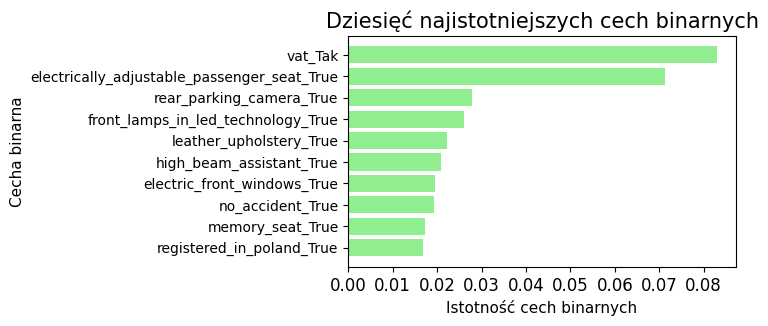

In [5]:
# Remove unnecessary variables
df4=df3.drop(['id','vat_margin','offer_from','category','offer_creation_date','financing_possibility','offer_title','show_offers_with_vin_number','location','version', 'color','color_type','generation'],axis=1).copy()
df3=df3.drop(['id','vat_margin','offer_from','category','offer_creation_date','financing_possibility','offer_title','show_offers_with_vin_number','location','version', 'color','color_type','generation'],axis=1).copy()

# Select columns from index 17 onward, which contain binary variables
X=df3.iloc[:,17:]
df3=df3.drop(df3.iloc[:,17:],axis=1).copy()
X=X.fillna(False)
X=X.replace('Tak',True)
y=df3['price']

# Remove binary columns with less than 1% variation
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.01)
selector.fit(X)
columns_to_remove = X.columns[~selector.get_support()]
X = selector.transform(X)

# Remove binary columns with less than 1% variation
df32 = df4.drop(columns=columns_to_remove, axis=1)
X=df32.iloc[:,17:]
X=X.fillna(0)
X = pd.get_dummies(X, drop_first=True)

# feature selection
import xgboost as xgb
import matplotlib.pyplot as plt

model = xgb.XGBRegressor()
model.fit(X, y)

xgb_importance = model.feature_importances_

sorted_idx = np.argsort(xgb_importance)[-10:]
plt.figure(figsize=(5, 3))
plt.barh(X.columns[sorted_idx], xgb_importance[sorted_idx], color='lightgreen')
plt.title("Dziesięć najistotniejszych cech binarnych", fontsize=15)
plt.xlabel("Istotność cech binarnych",fontsize=11)
plt.xticks(fontsize=12)
plt.ylabel('Cecha binarna', fontsize=11)

top_5_features = X.columns[sorted_idx][-5:]
plt.show()

## 1.2 Selected Features

Binary listing attributes are screened for low variation, and XGBoost feature importance is used to identify relevant features for the analysis.

### 1.2.1 Rebuilding the Selected Feature Set

Selected binary features are joined with the main dataset, and missing values in indicator columns are represented as false or “No”.

In [6]:
variables_to_add = ['leather_upholstery', 'front_lamps_in_led_technology', 'rear_parking_camera', 'electrically_adjustable_passenger_seat', 'vat','no_accident','damaged']
df3 = pd.concat([df3, df2[variables_to_add]], axis=1)
df3['vat']=df3['vat'].fillna('Nie')
df3['electrically_adjustable_passenger_seat']=df3['electrically_adjustable_passenger_seat'].fillna(False)
df3['leather_upholstery']=df3['leather_upholstery'].fillna(False)
df3['front_lamps_in_led_technology']=df3['front_lamps_in_led_technology'].fillna(False)
df3['rear_parking_camera']=df3['rear_parking_camera'].fillna(False)
df3['no_accident']=df3['no_accident'].fillna(False)
df3['damaged']=df3['damaged'].fillna(False)

# 2. Data Preparation and Transformation

This chapter converts source values into consistent analytical variables. It covers currency conversion, vehicle-condition filters, unit removal, derived age features, missing-data treatment, and explicit limits for extreme values. The resulting fields are then restricted to vehicle models with adequate representation and assigned modeling-ready data types.

## 2.1 Numeric Standardization and Vehicle Condition

Prices are converted to PLN, damaged or accident-affected offers are excluded, units are removed from numeric fields, and age-related features are derived.

In [7]:
# Convert prices to PLN
df3['price'] = df3['price'].astype(float)
df3.loc[df3['currency'] == 'EUR', 'price'] *= 4.29
df3=df3.drop('currency',axis=1)

# Remove damaged cars
filt=(df3['no_accident']==True)
df3=df3.loc[filt]
filt=(df3['damaged']=='Tak')
df3=df3.loc[~filt]
len(df3)

# Remove units from measurements
df3['mileage'] = df3['mileage'].str.replace(' km','').str.replace(' ','').astype(float)
df3['engine_displacement'] = df3['engine_displacement'].str.replace(' cm3','').str.replace(' ','').astype(float)
df3['power'] = df3['power'].str.replace(' KM','').str.replace(' ','').astype(float)

# Create the car_age column
df3['car_age'] = df3['production_year'].apply(lambda x: 2023 - x)
df3=df3.drop('production_year',axis=1)

# Create the seller_experience column
df3['seller_experience'] = df3['seller_registration_year'].apply(lambda x: 2023 - x)
df3=df3.drop('seller_registration_year',axis=1)
# Clean seller_experience errors: OtoMoto was founded in 2004, so it had operated for 19 years by 2023. The 30 values above 19 years are replaced with the mean.
filt=df3['seller_experience']>19
df3.loc[filt,'seller_experience']=df3['seller_experience'].mean()

## 2.2 Missing-Value Analysis

Missing values are considered according to the meaning of each feature. Engine displacement and mileage receive domain-specific treatment, while fields with substantial or less informative missingness are excluded. Remaining incomplete records are removed before outlier analysis.

In [8]:
df4=df3.copy()
df4.isnull().values.any()

np.True_

### 2.2.1 Engine Displacement

For electric and hydrogen vehicles, engine displacement is represented as zero. Other missing displacement values are filled with the column mean.

In [9]:
df4['engine_displacement'].isnull().sum()
filt=(df4['fuel_type']=='Electric') | (df4['fuel_type']=='Hyrdrogen')
df4.loc[filt]

,price,seller_type,vehicle_brand,vehicle_model,mileage,engine_displacement,fuel_type,power,transmission,body_type,...,fuel_consumption_in_city,leather_upholstery,front_lamps_in_led_technology,rear_parking_camera,electrically_adjustable_passenger_seat,vat,no_accident,damaged,car_age,seller_experience
370,307100.0,Authorized Dealer,Skoda,Enyaq,10.0,NaN,Electric,204.0,Automatic,SUV,...,NaN,False,True,True,False,Nie,True,False,0,4.0
614,662900.0,Authorized Dealer,Mercedes-Benz,EQS,5.0,NaN,Electric,360.0,Automatic,SUV,...,NaN,True,False,True,True,Tak,True,False,1,13.0
744,46900.0,Dealer,Renault,Zoe,97000.0,NaN,Electric,88.0,Automatic,Compact,...,NaN,False,False,False,False,Nie,True,False,9,4.0
808,230000.0,Authorized Dealer,Skoda,Enyaq,18906.0,NaN,Electric,204.0,Automatic,SUV,...,NaN,False,True,True,False,Tak,True,False,2,6.0
879,389900.0,Authorized Dealer,Jaguar,I-Pace,17950.0,NaN,Electric,400.0,NaN,SUV,...,NaN,False,True,False,True,Tak,True,False,1,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207889,264900.0,Dealer,Volkswagen,Inny,1.0,NaN,Electric,204.0,Automatic,SUV,...,NaN,False,False,True,False,Tak,True,False,1,3.0
208076,84900.0,Authorized Dealer,Renault,Zoe,36809.0,NaN,Electric,109.0,Automatic,Compact,...,NaN,False,False,True,False,Tak,True,False,5,5.0
208098,390000.0,Authorized Dealer,Mercedes-Benz,EQC,8000.0,NaN,Electric,408.0,Automatic,SUV,...,NaN,False,True,True,True,Tak,True,False,1,15.0
208181,249000.0,Private person,Tesla,Model S,171800.0,NaN,Electric,700.0,Automatic,Sedan,...,NaN,False,False,False,False,Tak,True,False,8,9.0


The remaining engine-displacement gaps are filled with the mean value.

In [10]:
df4.loc[filt, "engine_displacement"] = 0
df4["engine_displacement"].isnull().sum()
df4["engine_displacement"] = df4["engine_displacement"].fillna(
    df4["engine_displacement"].mean()
)


### 2.2.2 Number of Doors

Offers without a recorded number of doors are excluded from the dataset.

The number of missing door values is counted before those records are removed.

In [11]:
df4["number_of_doors"].isnull().sum()
filt = df4["number_of_doors"].isnull()
df4 = df4.loc[~filt]


### 2.2.3 Number of Seats

The number-of-seats field is reviewed and removed from the analysis.

Missing seat counts are counted before the column is dropped.

In [12]:
df4["number_of_seats"].isnull().sum()
df4 = df4.drop("number_of_seats", axis=1)


### 2.2.4 Fuel Consumption

City fuel consumption is reviewed and removed from the dataset.

The number of missing city fuel-consumption values is counted before the column is dropped.

In [13]:
df4["fuel_consumption_in_city"].isnull().sum()
df4 = df4.drop("fuel_consumption_in_city", axis=1)


### 2.2.5 Mileage

Mileage records are compared with vehicle state. Missing mileage for new cars is set to zero, and rows with other missing values are removed.

In [14]:
(df4['mileage'].isnull()).value_counts()

mileage
False    114707
True       1200
Name: count, dtype: int64

In [15]:
df4.loc[(df4['mileage'].isnull())]['state'].value_counts()

state
New    1200
Name: count, dtype: int64

Missing mileage for new vehicles is set to zero, after which complete records are selected.

In [16]:
df4.loc[df4["mileage"].isnull(), "mileage"] = 0
new_data = df4.dropna(axis=0, how="any")
# The dataset has 1,200 missing mileage values, all for new cars. They are assumed to be zero.


### 2.2.6 Remaining Missing Values

The remaining incomplete rows are counted, and their share of the dataset is calculated.

Rows with remaining missing values are excluded from the cleaned dataset.

In [17]:
((len(df4) - len(new_data)) / len(df4)) * 100
# Approximately 0.11% of the data had missing values. Since this is a very small proportion, those rows were removed from the analysis.
df4 = new_data.copy()


## 2.3 Outlier Analysis and Filtering

The numerical distributions and price relationships are reviewed before applying the study filters. Listings beyond the selected price, power, mileage, and vehicle-age limits are removed, and the sample is restricted to models with at least 100 observations. The resulting categorical and numerical fields are prepared for descriptive analysis and modeling.

### 2.3.1 Pre-filtering Visualizations

Scatter plots show price against mileage, engine displacement, power, vehicle age, and seller experience before filtering.

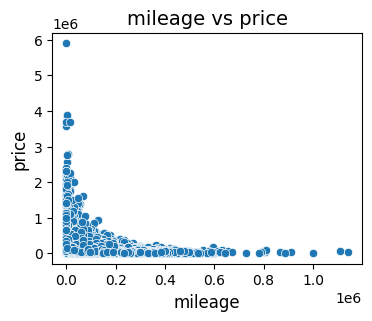

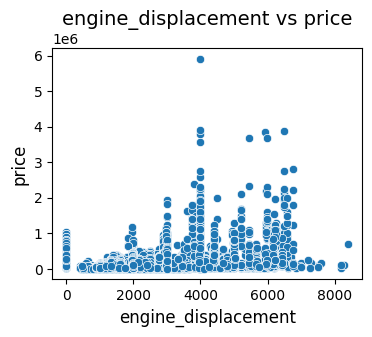

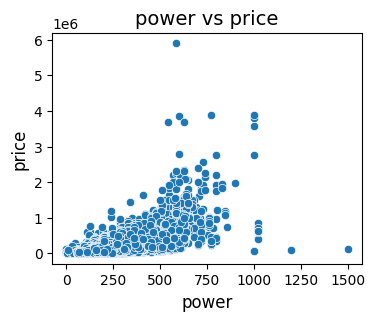

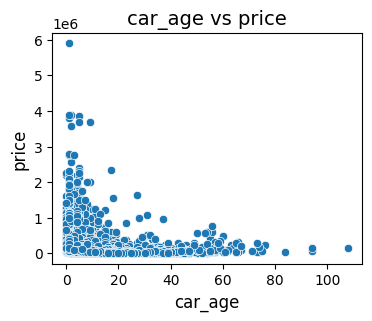

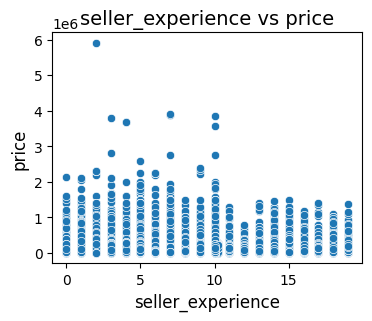

In [18]:
quantitative_vars = ['price', 'mileage', 'engine_displacement', 'power', 'car_age', 'seller_experience']
for var in quantitative_vars[1:]:
    plt.figure(figsize=(4, 3))
    sns.scatterplot(x=df4[var], y=df4['price'])
    plt.title(f'{var} vs price', fontsize=14)
    plt.xlabel(var, fontsize=12)
    plt.ylabel('price', fontsize=12)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.show()


### 2.3.2 Applying Filtering Thresholds

Listings are filtered using upper thresholds of PLN 1,500,000 for price, 800 hp for power, 1,500,000 km for mileage, and 60 years for vehicle age.

Listings priced above PLN 1,500,000 are removed.

In [19]:
filt = df4["price"] > 1500000
df4 = df4.loc[~filt]


In [20]:
filt=df4['power']>800
df4.loc[filt].count()

price                                     20
seller_type                               20
vehicle_brand                             20
vehicle_model                             20
mileage                                   20
engine_displacement                       20
fuel_type                                 20
power                                     20
transmission                              20
body_type                                 20
number_of_doors                           20
state                                     20
leather_upholstery                        20
front_lamps_in_led_technology             20
rear_parking_camera                       20
electrically_adjustable_passenger_seat    20
vat                                       20
no_accident                               20
damaged                                   20
car_age                                   20
seller_experience                         20
dtype: int64

Vehicles with recorded power above 800 hp are removed.

In [21]:
filt = df4["power"] > 800
df4 = df4.loc[~filt]


Listings with mileage above 1,500,000 km are removed.

In [22]:
filt = df4["mileage"] > 1500000
df4 = df4.loc[~filt]


Vehicles older than 60 years are removed.

In [23]:
filt = df4["car_age"] > 60
df4 = df4.loc[~filt]


## 2.4 Model Frequency Selection

The analysis retains vehicle models with at least 100 listings.

In [24]:
len(df4)

115665

Listing counts are calculated for each vehicle model.

In [25]:
list = df4["vehicle_model"].value_counts()


Models represented by at least 100 listings are selected for the cleaned dataset.

In [26]:
filtered_models = list[list >= 100].index
df5 = df4[df4["vehicle_model"].isin(filtered_models)]


In [27]:
list[list >= 100].head(10)

vehicle_model
Octavia     2499
Astra       2466
A4          2155
Seria 3     2064
Seria 5     1980
Golf        1976
Focus       1906
Passat      1840
A6          1779
Insignia    1522
Name: count, dtype: int64

In [28]:
list[list >= 100].tail(20)

vehicle_model
Eclipse Cross        110
Leaf                 110
Captiva              109
Elantra              109
C5X                  108
9.mar                108
EQS                  108
C3 Picasso           107
Jogger               106
Jimny                106
V90 Cross Country    104
CX-30                103
Niro                 101
Tiguan Allspace      100
Ranger               100
Q2                   100
i10                  100
Altea XL             100
Cooper S             100
Modus                100
Name: count, dtype: int64

## 2.5 Manufacturer and Model Labels

Vehicle model names are considered together with their manufacturers when examining repeated labels.

Ferrari records are reviewed in the context of model names shared by different manufacturers.

In [29]:
ferrari_data = df5[df5['vehicle_brand'] == 'Ferrari']
ferrari_data

,price,seller_type,vehicle_brand,vehicle_model,mileage,engine_displacement,fuel_type,power,transmission,body_type,...,state,leather_upholstery,front_lamps_in_led_technology,rear_parking_camera,electrically_adjustable_passenger_seat,vat,no_accident,damaged,car_age,seller_experience
53663,646000.0,Authorized Dealer,Ferrari,California,68289.0,4297.0,Gasoline,460.0,Automatic,Cabriolet,...,Used,False,False,True,True,Nie,True,False,9,10.0
83835,750000.0,Private person,Ferrari,California,14950.0,3855.0,Gasoline,560.0,Automatic,Cabriolet,...,Used,True,False,True,True,Nie,True,False,7,9.0


The Ferrari records are removed from the modeling dataset.

In [30]:
df5 = df5[df5["vehicle_brand"] != "Ferrari"]


In [31]:
# Remove all models labeled as “other”
df5 = df5[df5["vehicle_model"] != "Inny"]


In [32]:
ferrari_data = df5[df5['vehicle_brand'] == 'Ferrari']
ferrari_data

,price,seller_type,vehicle_brand,vehicle_model,mileage,engine_displacement,fuel_type,power,transmission,body_type,...,state,leather_upholstery,front_lamps_in_led_technology,rear_parking_camera,electrically_adjustable_passenger_seat,vat,no_accident,damaged,car_age,seller_experience


## 2.6 Data Types

Categorical fields are assigned category types, continuous fields are converted to numeric types, and temporary condition flags are removed.

The retained feature columns are converted to their analysis data types and prepared for export.

In [33]:
categorical_columns = [
    "seller_type",
    "fuel_type",
    "vehicle_model",
    "vehicle_brand",
    "transmission",
    "body_type",
    "number_of_doors",
    "state",
    "leather_upholstery",
    "front_lamps_in_led_technology",
    "rear_parking_camera",
    "electrically_adjustable_passenger_seat",
    "vat",
]
numeric_features = [
    "price",
    "power",
    "mileage",
    "car_age",
    "engine_displacement",
    "seller_experience",
]
df5[categorical_columns] = df5[categorical_columns].astype("category")
df5.drop(columns=["damaged"], inplace=True)
df5.drop(columns=["no_accident"], inplace=True)
df5[numeric_features] = df5[numeric_features].astype(np.float32)


# 3. Dataset Overview and Exploratory Analysis

This chapter describes the composition and structure of the cleaned vehicle sample. It examines numeric distributions, correlations with price, category frequencies, and comparisons across manufacturers, models, and fuel types. The chapter concludes by exporting the processed dataset used in the separate tuning notebook.

## 3.1 Correlations and Variable Distributions

One-hot encoded features are ranked by the absolute value of their correlation with price, and the 15 highest-ranked features are displayed in a heatmap.

Index(['price', 'power', 'car_age', 'mileage', 'transmission_Manual',
       'vat_Tak', 'state_Used', 'engine_displacement',
       'rear_parking_camera_True', 'front_lamps_in_led_technology_True',
       'electrically_adjustable_passenger_seat_True',
       'leather_upholstery_True', 'seller_type_Private person',
       'vehicle_brand_Mercedes-Benz', 'vehicle_brand_Porsche'],
      dtype='object')


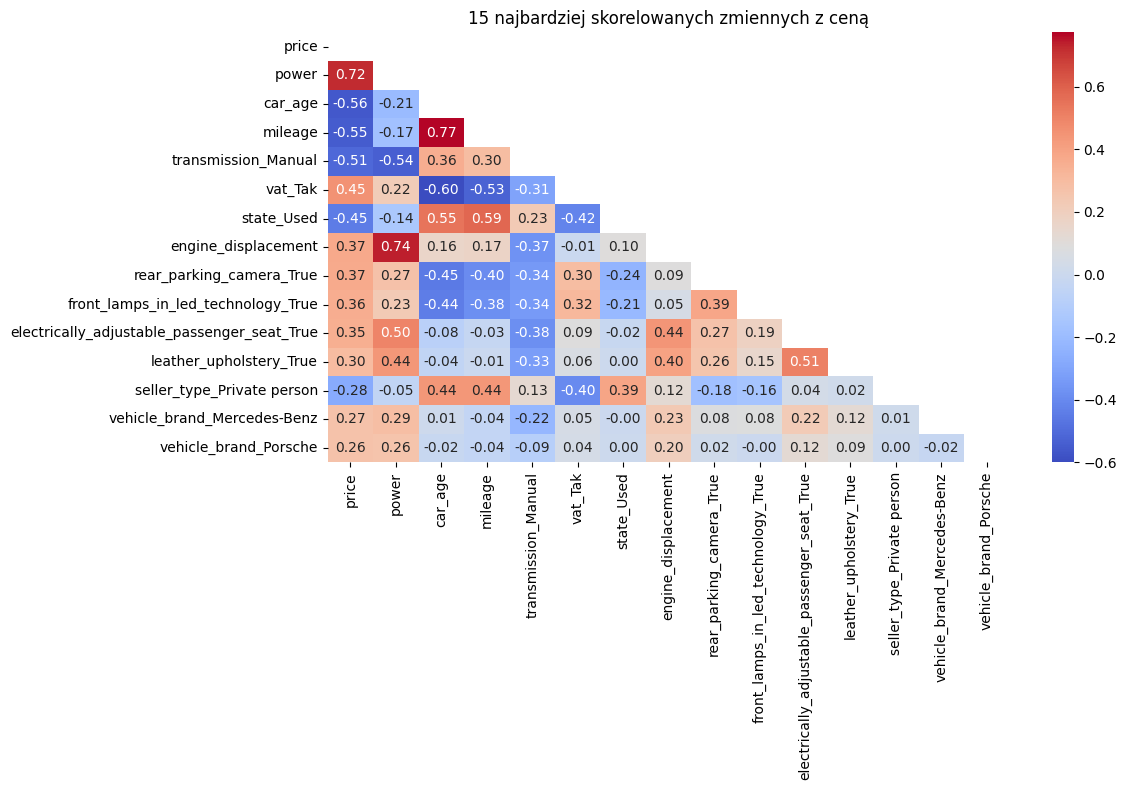

In [34]:
import seaborn as sns


df_encoded = pd.get_dummies(df5.drop(columns=['vehicle_model']), drop_first=True)

correlations = df_encoded.corr()['price'].abs().sort_values(ascending=False)

top_15_features = correlations.index[0:15]


import matplotlib.pyplot as plt

print(top_15_features)


plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(df_encoded[top_15_features].corr(), dtype=bool))
sns.heatmap(df_encoded[top_15_features].corr(), mask=mask, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("15 najbardziej skorelowanych zmiennych z ceną")
plt.tight_layout()
plt.show()

### 3.1.1 Numerical Features and Price

Scatter plots compare each numerical feature with vehicle price.

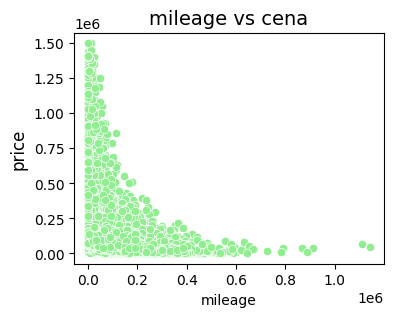

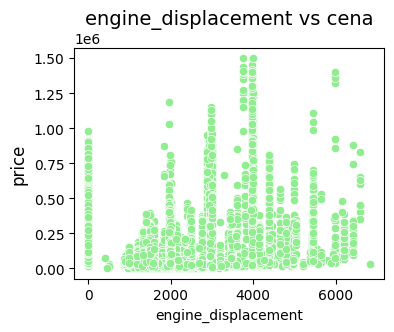

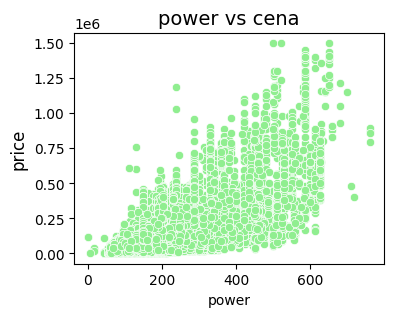

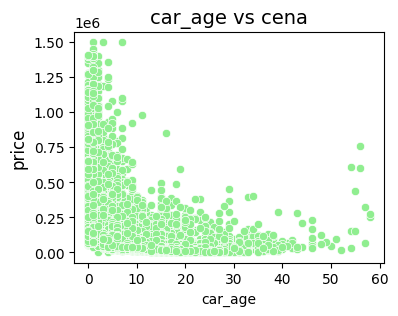

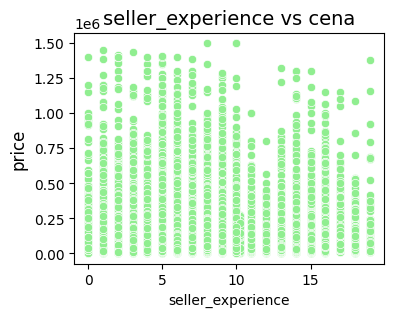

In [35]:
quantitative_vars = ['price', 'mileage', 'engine_displacement', 'power', 'car_age', 'seller_experience']
for var in quantitative_vars[1:]:
    plt.figure(figsize=(4, 3))
    sns.scatterplot(x=df5[var], y=df5['price'], color='lightgreen')
    plt.title(f'{var} vs cena', fontsize=14)
    plt.ylabel('price', fontsize=12)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.show()

### 3.1.2 Feature Distributions

Kernel-density plots display the distributions of price and the numerical predictors.

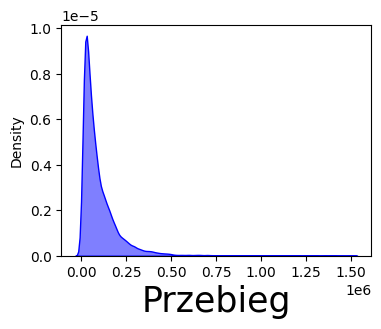

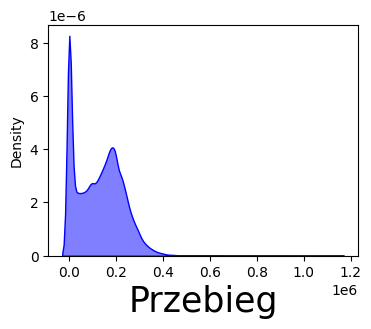

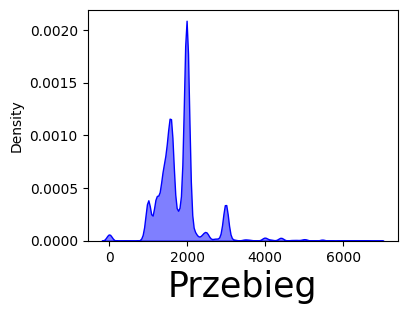

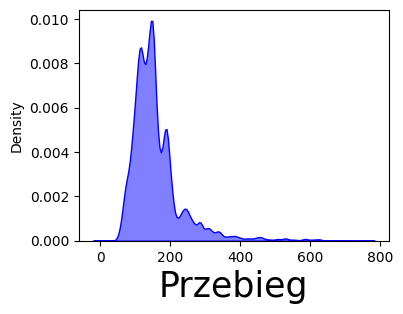

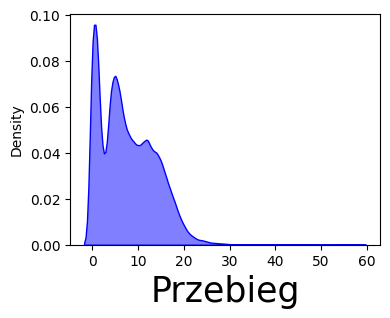

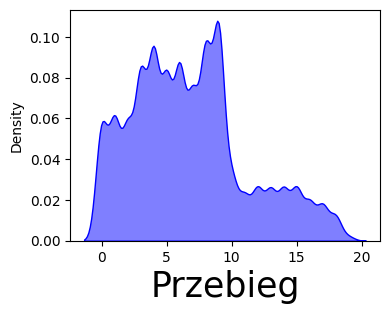

In [36]:
for var in quantitative_vars:
    plt.figure(figsize=(4, 3))
    sns.kdeplot(df5[var], fill=True, color="blue", alpha=0.5)
    plt.xlabel('Przebieg', fontsize=25)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.show()


## 3.2 Exploratory Data Analysis

The exploratory analysis moves from overall numerical summaries to categorical frequencies and group-level visualizations. Together, these views characterize the price range, vehicle age and mileage, and the representation of manufacturers, models, and fuel types in the final sample.

### 3.2.1 Descriptive Statistics

Summary statistics describe the numeric fields, followed by categorical summaries and comparisons across vehicle groups.

### 3.2.2 Fuel-Type Selection

Thirty listings with CNG fuel type and records without a fuel type are removed before the category summaries.

In [37]:
# Remove 30 vehicles with CNG engines
df5 = df5[df5['fuel_type'] != 'Gasoline + CNG']
df5 = df5[df5['fuel_type'].notna()]  
df5 = df5[df5['fuel_type'] != '']    
df5.describe().round(2)

,price,mileage,engine_displacement,power,car_age,seller_experience
count,99591.00,99591.00,99591.00,99591.00,99591.00,99591.00
mean,98905.93,126940.36,1806.73,158.87,7.72,6.77
std,111747.43,96641.97,642.69,74.86,5.96,4.45
min,1880.00,0.00,0.00,1.00,0.00,0.00
25%,31900.00,33347.00,1482.00,115.00,3.00,3.00
50%,63500.00,130260.00,1796.00,142.00,7.00,6.00
75%,126715.00,198600.00,1995.00,182.00,12.00,9.00
max,1500000.00,1142257.00,6834.00,761.00,58.00,19.00


### 3.2.3 Descriptive Results

The cleaned dataset contains 99,591 listings. Mean price is PLN 98,906 and median price is PLN 63,500. Median mileage is 130,260 km, and median vehicle age is 7 years.

### 3.2.4 Categorical Feature Summaries

Pivot tables and frequency summaries describe selected vehicle states and equipment categories.

In [38]:
pivot_table = pd.pivot_table(df5, values='car_age', index='state', columns='rear_parking_camera', aggfunc='mean')
print(pivot_table)
pivot_table = pd.pivot_table(df5, values='car_age', index='state', columns='vat', aggfunc='mean')
print(pivot_table)
pivot_table = pd.pivot_table(df5, values='car_age', index='state', columns='leather_upholstery', aggfunc='mean')
print(pivot_table)
pivot_table = pd.pivot_table(df5, values='car_age', index='state', columns='front_lamps_in_led_technology', aggfunc='mean')
print(pivot_table)
pivot_table = pd.pivot_table(df5, values='car_age', index='state', columns='electrically_adjustable_passenger_seat', aggfunc='mean')
print(pivot_table)

for col in categorical_columns:
    pivot_table = pd.pivot_table(df5, values='car_age', index=col, aggfunc='mean')
    print(f"Średnia wartość dla {col}:")
    print(pivot_table)

rear_parking_camera      False      True
state                                   
New                   0.390266  0.400741
Used                 10.729260  5.526989
vat          Nie       Tak
state                     
New     0.424188  0.391039
Used   10.948462  4.665787
leather_upholstery     False      True
state                                 
New                 0.386714  0.438776
Used                9.336811  8.491899
front_lamps_in_led_technology      False      True
state                                             
New                             0.396051  0.397223
Used                           10.488934  4.461479
electrically_adjustable_passenger_seat     False      True
state                                                     
New                                     0.390408  0.421211
Used                                    9.400393  8.137333
Średnia wartość dla seller_type:
                     car_age
seller_type                 
Authorized Dealer   2.031141
Dealer      

In [39]:
categorical_columns = [
    'seller_type', 'body_type', 'number_of_doors', 'state', 'fuel_type', 'transmission', 'leather_upholstery',
    'front_lamps_in_led_technology', 'rear_parking_camera', 'electrically_adjustable_passenger_seat', 'vat'
]

for col in categorical_columns:
    pivot_table = pd.pivot_table(df5, values='price', index=col, aggfunc='mean')
    print(f"Średnia cena dla {col}:")
    print(pivot_table)

Średnia cena dla seller_type:
                           price
seller_type                     
Authorized Dealer  178498.203125
Dealer              97820.757812
Private person      63490.757812
Średnia cena dla body_type:
                       price
body_type                   
Cabriolet      212150.671875
City cars       42216.820312
Compact         60548.203125
Coupe          208185.875000
Minivan         66068.742188
SUV            138195.421875
Sedan          130205.507812
Small cars      40663.394531
Station wagon   70018.250000
Średnia cena dla number_of_doors:
                         price
number_of_doors               
2.0              237633.578125
3.0               37294.515625
4.0              143355.937500
5.0               93390.414062
6.0               44598.078125
Średnia cena dla state:
               price
state               
New    210606.828125
Used    76695.632812
Średnia cena dla fuel_type:
                        price
fuel_type                    
Diesel     

In [40]:
categorical_columns = [
    'seller_type', 'body_type', 'number_of_doors', 'state', 'fuel_type', 'transmission', 'leather_upholstery',
    'front_lamps_in_led_technology', 'rear_parking_camera', 'electrically_adjustable_passenger_seat', 'vat'
]

for col in categorical_columns:
    pivot_table = pd.pivot_table(df5, values='car_age', index=col, aggfunc='mean')
    print(f"Średnia wiek dla {col}:")
    print(pivot_table)

Średnia wiek dla seller_type:
                     car_age
seller_type                 
Authorized Dealer   2.031141
Dealer              7.268904
Private person     10.692993
Średnia wiek dla body_type:
                 car_age
body_type               
Cabriolet      13.252818
City cars       9.158725
Compact         8.460017
Coupe           7.956025
Minivan        10.061552
SUV             5.439507
Sedan           7.979674
Small cars      8.983854
Station wagon   8.668861
Średnia wiek dla number_of_doors:
                   car_age
number_of_doors           
2.0              11.032696
3.0              13.044245
4.0               8.081730
5.0               7.398060
6.0              13.000000
Średnia wiek dla state:
        car_age
state          
New    0.396598
Used   9.172330
Średnia wiek dla fuel_type:
                  car_age
fuel_type                
Diesel           8.616547
Electric         1.628601
Gasoline         7.354427
Gasoline + LPG  10.917546
Hybrid           2.155324
Ś

Średnia wiek dla electrically_adjustable_passenger_seat:
                                         car_age
electrically_adjustable_passenger_seat          
False                                   7.937125
True                                    6.739342
Średnia wiek dla vat:
       car_age
vat           
Nie  10.480965
Tak   3.087369


In [41]:
for col in categorical_columns:
    print(f"Liczność dla {col}:")
    print(df5[col].value_counts())
    print()


Liczność dla seller_type:
seller_type
Private person       43188
Dealer               36686
Authorized Dealer    19717
Name: count, dtype: int64

Liczność dla body_type:
body_type
SUV              30400
Station wagon    20955
Compact          15469
Sedan            13579
Minivan           7847
City cars         6464
Coupe             2274
Small cars        1982
Cabriolet          621
Name: count, dtype: int64

Liczność dla number_of_doors:
number_of_doors
5.0    84530
4.0    10082
3.0     3345
2.0     1621
6.0       13
Name: count, dtype: int64

Liczność dla state:
state
Used    83073
New     16518
Name: count, dtype: int64

Liczność dla fuel_type:
fuel_type
Gasoline          48165
Diesel            43575
Hybrid             4320
Gasoline + LPG     2559
Electric            972
Gasoline + CNG        0
Name: count, dtype: int64

Liczność dla transmission:
transmission
Manual       55686
Automatic    43905
Name: count, dtype: int64

Liczność dla leather_upholstery:
leather_upholstery
False

### 3.2.5 Group Comparisons

The visualizations compare vehicle prices, listing frequencies, and fuel types across the cleaned sample.

#### 3.2.5.1 Average Prices by Manufacturer

Average prices are compared for manufacturers with the highest and lowest mean prices in the sample.

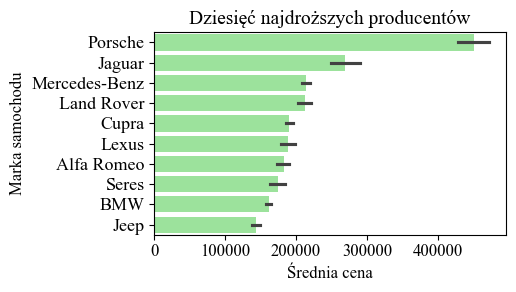

In [42]:
plt.rcParams['font.family'] = 'Times New Roman'
top_10_brands = df5.groupby('vehicle_brand')['price'].mean().nlargest(10).index
filtered_df = df5[df5['vehicle_brand'].isin(top_10_brands)]

plt.figure(figsize=(5,3))
sns.barplot(
    x=filtered_df['price'],
    y=filtered_df['vehicle_brand'],
    orient='h',
    order=top_10_brands,
    color='lightgreen'
)
plt.title('Dziesięć najdroższych producentów', fontsize=14)
plt.xlabel('Średnia cena', fontsize=12)
plt.ylabel('Marka samochodu', fontsize=12)
plt.tight_layout()

plt.yticks(fontsize=13)
plt.xticks(fontsize=12)
plt.show()

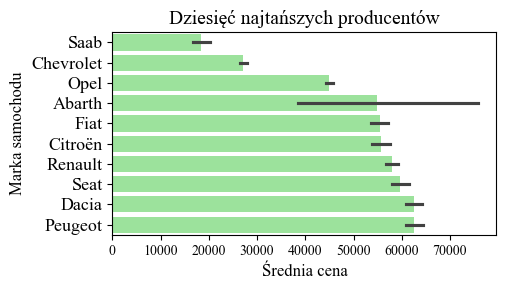

In [43]:
top_10_brands = df5.groupby('vehicle_brand')['price'].mean().nsmallest(10).index
filtered_df = df5[df5['vehicle_brand'].isin(top_10_brands)]

plt.figure(figsize=(5,3))
sns.barplot(
    x=filtered_df['price'],
    y=filtered_df['vehicle_brand'],
    orient='h',
    order=top_10_brands,
    color='lightgreen'
)
plt.title('Dziesięć najtańszych producentów',fontsize=14)
plt.xlabel('Średnia cena',fontsize=12)
plt.ylabel('Marka samochodu',fontsize=12)

plt.tight_layout()
plt.yticks(fontsize=13)

plt.xticks(fontsize=10)
plt.show()

#### 3.2.5.2 Listing Frequencies

The charts show the ten most frequently listed manufacturers and the ten most frequently listed vehicle models.

vehicle_brand
BMW              9599
Volkswagen       9084
Audi             8378
Opel             7626
Ford             7554
Skoda            6795
Mercedes-Benz    6302
Renault          4980
Toyota           4368
Hyundai          4009
Name: count, dtype: int64


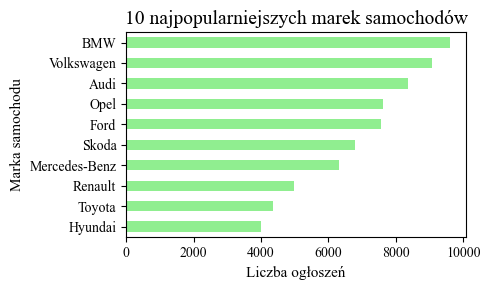

In [44]:
most_popular_brands = df5['vehicle_brand'].value_counts().nlargest(10)
print(most_popular_brands)

ax = most_popular_brands.iloc[::-1].plot(kind='barh', color='lightgreen', figsize=(5,3))
ax.set_title('10 najpopularniejszych marek samochodów',fontsize=14)
ax.set_xlabel('Liczba ogłoszeń',fontsize=11)
ax.set_ylabel('Marka samochodu',fontsize=11)
plt.tight_layout()
plt.show()




vehicle_model
Octavia     2496
Astra       2465
A4          2155
Seria 3     2064
Seria 5     1980
Golf        1974
Focus       1905
Passat      1838
A6          1779
Insignia    1522
Name: count, dtype: int64


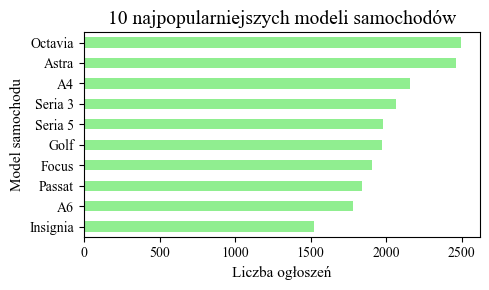

In [45]:
most_popular_brands = df5['vehicle_model'].value_counts().nlargest(10)
print(most_popular_brands)

ax = most_popular_brands.iloc[::-1].plot(kind='barh', color='lightgreen',figsize=(5,3))
ax.set_title('10 najpopularniejszych modeli samochodów',fontsize=14)
ax.set_xlabel('Liczba ogłoszeń',fontsize=11)
ax.set_ylabel('Model samochodu',fontsize=11)
plt.tight_layout()
plt.show()

#### 3.2.5.3 Fuel-Type Distribution

The distribution of listings across fuel types is visualized.

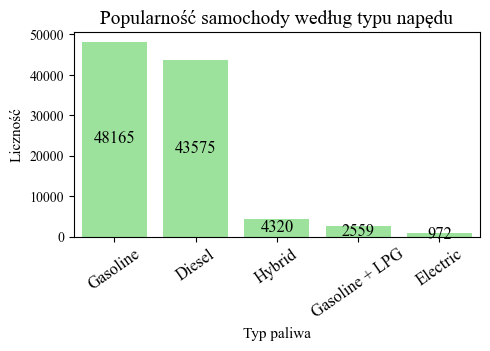

In [46]:


if hasattr(df5['fuel_type'], 'cat'):
    df5['fuel_type'] = df5['fuel_type'].cat.remove_unused_categories()

plt.figure(figsize=(5,3))
ax = sns.countplot(x=df5['fuel_type'], order=df5['fuel_type'].value_counts().index, color='lightgreen')
plt.title('Popularność samochody według typu napędu',fontsize=14)
plt.xlabel('Typ paliwa',fontsize=11)
plt.ylabel('Liczność',fontsize=11)

plt.tight_layout()
plt.xticks(fontsize=12, rotation=35)
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
        ha='center', va='center', fontsize=12, color='black'
    )

plt.show()


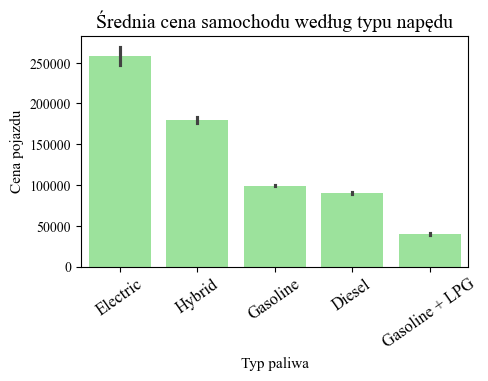

In [47]:
plt.rcParams['font.family'] = 'Times New Roman'

plt.figure(figsize=(5,3))
sns.barplot(
    x=df5['fuel_type'],
    y=df5['price'],
    color='lightgreen',
    order=df5.groupby('fuel_type')['price'].mean().sort_values(ascending=False).index
)
plt.title('Średnia cena samochodu według typu napędu', fontsize=14, fontname='Times New Roman')
plt.xlabel('Typ paliwa', fontsize=11, fontname='Times New Roman')
plt.ylabel('Cena pojazdu', fontsize=11, fontname='Times New Roman')
plt.xticks(fontsize=12, rotation=35)
plt.show()

## 3.3 Processed Dataset Export

The cleaned and typed dataset is exported as `dane_po_transformacji.csv` for use in the parameter-tuning analysis.

In [48]:
df5.to_csv("dane_po_transformacji.csv")


## 3.4 Categorical and Binary Feature Counts

Frequency counts summarize the selected categorical and binary features.

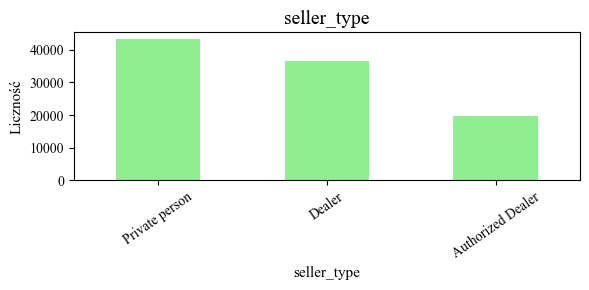

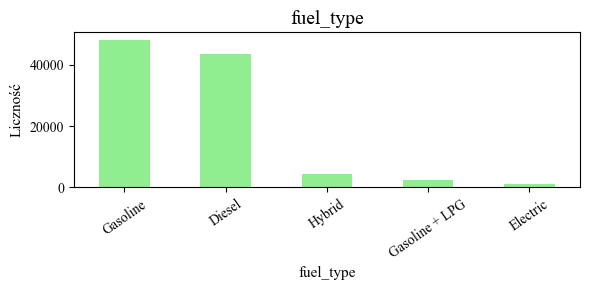

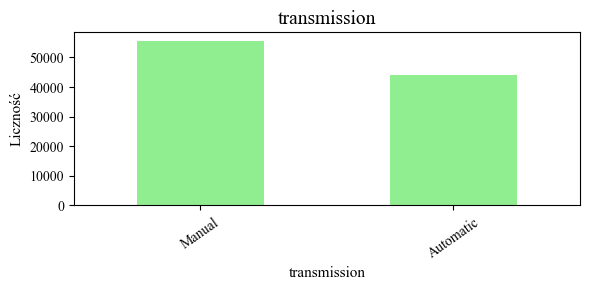

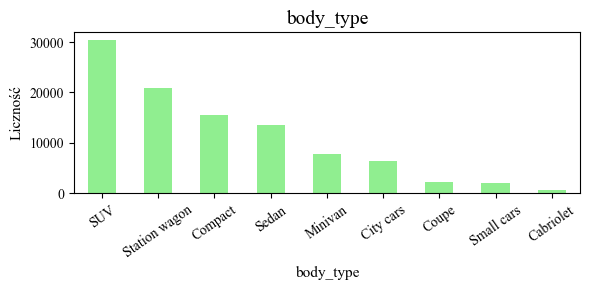

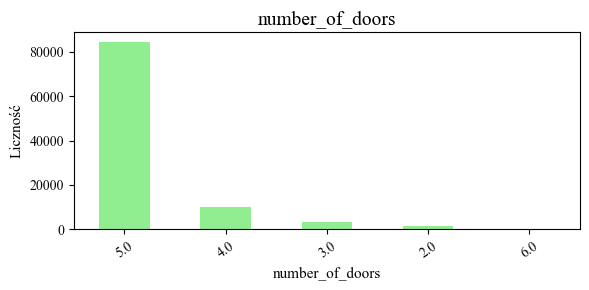

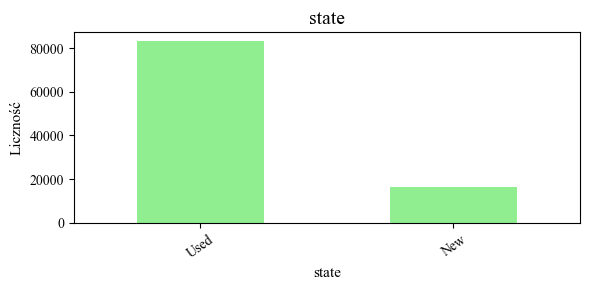

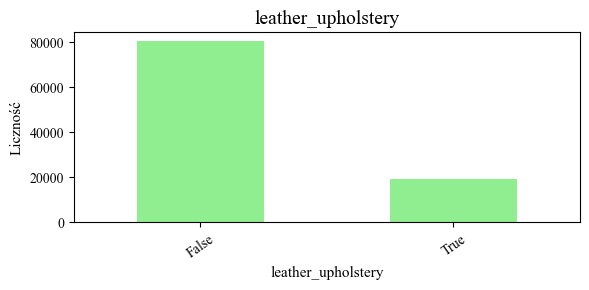

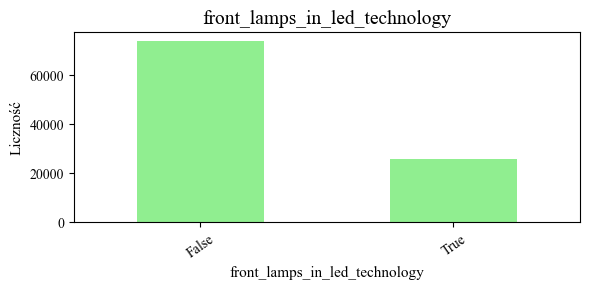

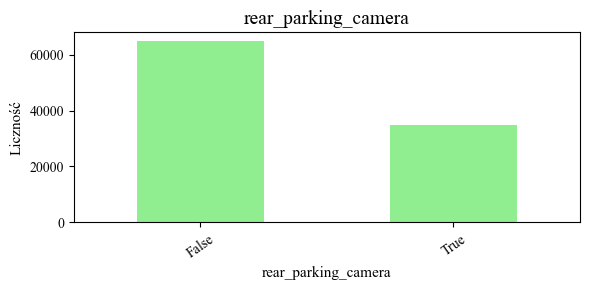

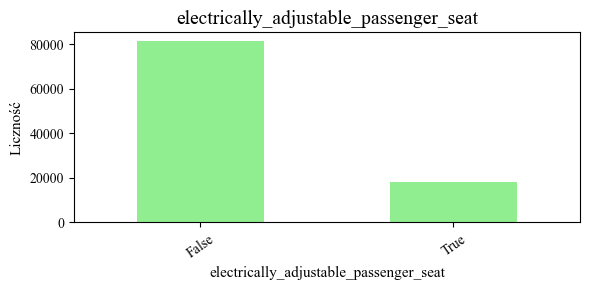

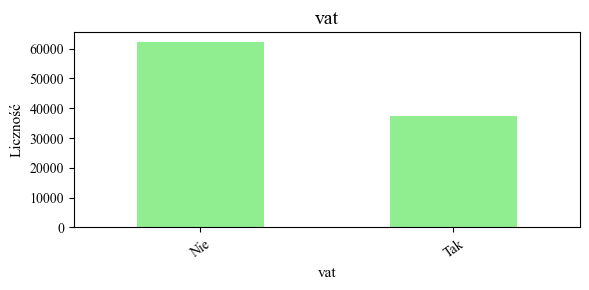

In [49]:
categorical_columns = [
    'seller_type', 'fuel_type', 'transmission', 'body_type',
    'number_of_doors', 'state', 'leather_upholstery', 'front_lamps_in_led_technology',
    'rear_parking_camera', 'electrically_adjustable_passenger_seat', 'vat'
]

for col in categorical_columns:
    plt.figure(figsize=(6, 3))
    df5[col].value_counts().plot(kind='bar', color='#90ee90')  
    plt.title(f'{col}',fontsize=14)
    plt.xlabel(f'{col}',fontsize=11)
    plt.ylabel('Liczność',fontsize=11)
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# 4. Modeling and Diagnostics

This chapter evaluates ordinary linear regression, Ridge regression, Random Forest, multilayer perceptron, and XGBoost models. Each model family is considered with price, log(price), and square-root(price) as the target; transformed predictions are returned to the price scale for evaluation. Feature preparation, a fixed train-test split, and residual diagnostics provide a common framework for comparing the model variants.

Hyperparameter searches for Ridge, Random Forest, MLP, and XGBoost are presented in `ParameterTuning.ipynb`.

## 4.1 Target Transformations

Price, log(price), and square-root(price) are used as target representations. Predictions from transformed targets are converted back to prices for evaluation.

The manufacturer field is excluded from the model inputs, and logarithmic and square-root target variants are created.

In [50]:
df5 = df5.drop("vehicle_brand", axis=1)
df4_log = df5.copy()
df4_log["price"] = np.log(df4_log["price"])

df4_sqrt = df5.copy()
df4_sqrt["price"] = np.sqrt(df4_sqrt["price"])


## 4.2 Feature Preprocessing

Numerical features are standardized and categorical features are one-hot encoded to produce model-ready matrices.

A column transformer applies standard scaling to numerical fields and one-hot encoding to categorical fields.

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_absolute_error

numeric_features = [
    "power",
    "mileage",
    "car_age",
    "engine_displacement",
    "seller_experience",
]
numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])

categorical_features = [
    "seller_type",
    "fuel_type",
    "vehicle_model",
    "transmission",
    "body_type",
    "number_of_doors",
    "state",
    "leather_upholstery",
    "front_lamps_in_led_technology",
    "rear_parking_camera",
    "electrically_adjustable_passenger_seat",
    "vat",
]
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)


y = df5["price"]
X = df5.drop("price", axis=1)
X_preprocessed = preprocessor.fit_transform(X)
y_log = df4_log["price"]
X_log = df4_log.drop("price", axis=1)
X_log_preprocessed = preprocessor.fit_transform(X_log)

y_sqrt = df4_sqrt["price"]
X_sqrt = df4_sqrt.drop("price", axis=1)
X_sqrt_preprocessed = preprocessor.fit_transform(X_sqrt)


## 4.3 Train-Test Split

The observations are split into 80% training data and 20% test data using a fixed random seed.

The same split settings are applied to the original, log-transformed, and square-root-transformed targets.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X_preprocessed, y, test_size=0.2, random_state=0, shuffle=True
)

X_log_train, X_log_test, y_log_train, y_log_test = train_test_split(
    X_log_preprocessed, y_log, test_size=0.2, random_state=0, shuffle=True
)

X_sqrt_train, X_sqrt_test, y_sqrt_train, y_sqrt_test = train_test_split(
    X_sqrt_preprocessed, y_sqrt, test_size=0.2, random_state=0, shuffle=True
)


In [53]:
X_train.shape

(79672, 289)

## 4.4 Linear Regression: Original Target

Multiple linear regression is fitted to the original price target, and test-set predictions are evaluated using MAPE and MAE.

In [71]:
from sklearn.linear_model import LinearRegression

regresja = LinearRegression()
regresja.fit(X_train, y_train)

y_pred_Reg = regresja.predict(X_test)
MAPE_Reg = mean_absolute_percentage_error(y_test, y_pred_Reg)
MAE_Reg = mean_absolute_error(y_pred_Reg, y_test)


### 4.4.1 Residual Plots

Residual-versus-fitted, residual histogram, and Q-Q plots summarize the diagnostics for the model fitted to price.

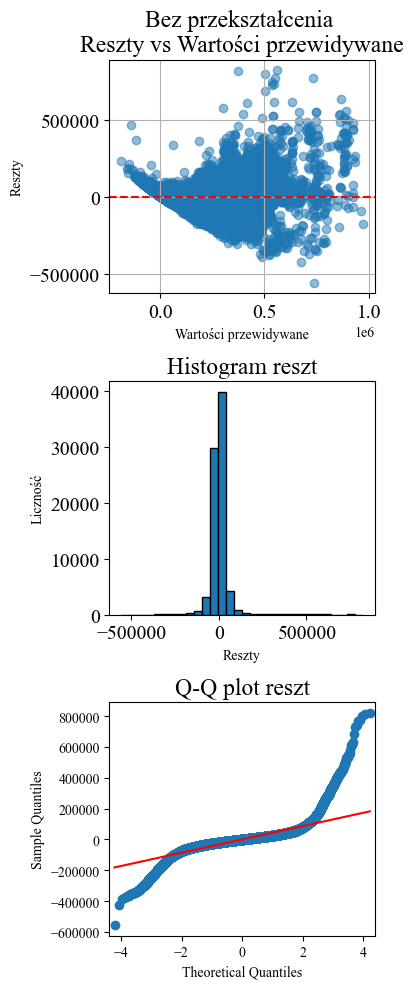

In [72]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

import scipy.stats as stats


y_train_pred = regresja.predict(X_train)
residuals = y_train - y_train_pred


fig, axs = plt.subplots(3, 1, figsize=(4, 10))

# 1. Residuals vs. predicted values
axs[0].scatter(y_train_pred, residuals, alpha=0.5)
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel('Wartości przewidywane')
axs[0].set_ylabel('Reszty')
axs[0].set_title('Bez przekształcenia \nReszty vs Wartości przewidywane', fontsize=17)
axs[0].grid()
axs[0].tick_params(axis='x', labelsize=14)
axs[0].tick_params(axis='y', labelsize=14)

# 2. Residual histogram
axs[1].hist(residuals, bins=30, edgecolor='k')
axs[1].set_title('Histogram reszt', fontsize=17)
axs[1].set_xlabel('Reszty')
axs[1].set_ylabel('Liczność')
axs[1].tick_params(axis='x', labelsize=14)
axs[1].tick_params(axis='y', labelsize=14)

# 3. Residual Q-Q plot
import statsmodels.api as sm
sm.qqplot(residuals, line='s', ax=axs[2])
axs[2].set_title('Q-Q plot reszt',fontsize=17)

plt.tight_layout()
plt.show()



#### 4.4.2 Residual Diagnostics

Diagnostic statistics summarize residual autocorrelation, homoscedasticity, normality, and multicollinearity.

In [75]:
from statsmodels.stats.diagnostic import het_goldfeldquandt

dw = durbin_watson(residuals)
print(f'Wartość statystyki Durbin-Watsona: {dw:.2f}')

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f'Shapiro-Wilk test: stat={shapiro_stat:.4f}, p-value={shapiro_p:.4g}')

X = sm.add_constant(X_train.toarray())
gq_test = het_goldfeldquandt(y_train, X)
print(f"Goldfeld-Quandt test: stat={gq_test[0]:.4f}, p-value={gq_test[1]:.4g}")

Wartość statystyki Durbin-Watsona: 2.00
Shapiro-Wilk test: stat=0.7662, p-value=3.269e-131
Goldfeld-Quandt test: stat=1.0228, p-value=0.01248


## 4.5 Linear Regression: Log-Transformed Target

Multiple linear regression is fitted to log(price), and exponentiated test predictions are evaluated in PLN.

In [67]:
regresja.fit(X_log_train, y_log_train)
y_pred_Reg_log = regresja.predict(X_log_test)
MAPE_Reg_log = mean_absolute_percentage_error(
    np.exp(y_log_test), np.exp(y_pred_Reg_log)
)
MAE_Reg_log = mean_absolute_error(np.exp(y_pred_Reg_log), np.exp(y_log_test))


### 4.5.1 Residual Plots

Residual plots summarize the log-target model after predictions are converted back to the price scale.

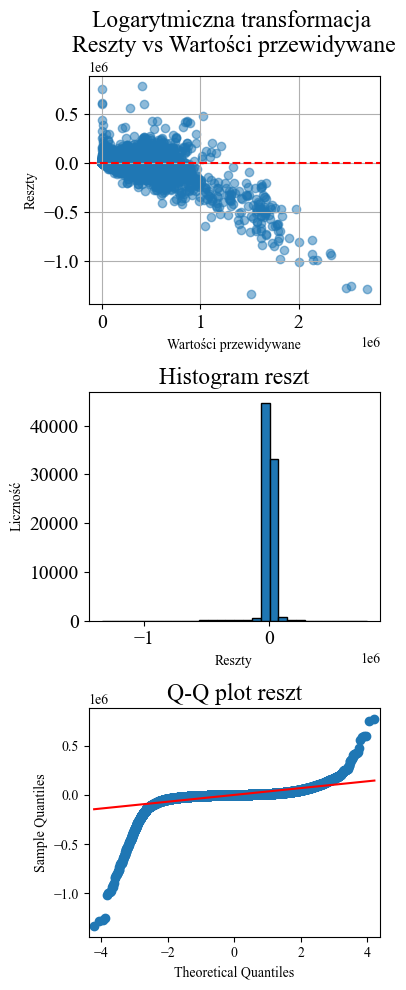

In [58]:
y_log_train_pred = regresja.predict(X_log_train)
residuals = np.exp(y_log_train) - np.exp(y_log_train_pred)


fig, axs = plt.subplots(3, 1, figsize=(4, 10))

# 1. Residuals vs. predicted values
axs[0].scatter(np.exp(y_log_train_pred), residuals, alpha=0.5)
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel('Wartości przewidywane')
axs[0].set_ylabel('Reszty')
axs[0].set_title('Logarytmiczna transformacja \nReszty vs Wartości przewidywane', fontsize=17)
axs[0].grid()
axs[0].tick_params(axis='x', labelsize=14)
axs[0].tick_params(axis='y', labelsize=14)

# 2. Residual histogram
axs[1].hist(residuals, bins=30, edgecolor='k')
axs[1].set_title('Histogram reszt', fontsize=17)
axs[1].set_xlabel('Reszty')
axs[1].set_ylabel('Liczność')
axs[1].tick_params(axis='x', labelsize=14)
axs[1].tick_params(axis='y', labelsize=14)

# 3. Residual Q-Q plot
import statsmodels.api as sm
sm.qqplot(residuals, line='s', ax=axs[2])
axs[2].set_title('Q-Q plot reszt', fontsize=17)

plt.tight_layout()
plt.show()



#### 4.5.2 Residual Diagnostics

Residual diagnostics are calculated for the model fitted to log(price).

In [76]:
from statsmodels.stats.diagnostic import het_goldfeldquandt

import statsmodels.api as sm


dw = durbin_watson(residuals)
print(f'Wartość statystyki Durbin-Watsona: {dw:.2f}')


shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f'Shapiro-Wilk test: stat={shapiro_stat:.4f}, p-value={shapiro_p:.4g}')


X = sm.add_constant(X_log_train.toarray())
gq_test = het_goldfeldquandt(y_log_train, X)
print(f"Goldfeld-Quandt test: stat={gq_test[0]:.4f}, p-value={gq_test[1]:.4g}")



Wartość statystyki Durbin-Watsona: 2.00
Shapiro-Wilk test: stat=0.7662, p-value=3.269e-131
Goldfeld-Quandt test: stat=1.0214, p-value=0.01765


## 4.6 Linear Regression: Square-Root-Transformed Target

Multiple linear regression is fitted to square-root(price), and squared test predictions are evaluated in PLN.

In [77]:
regresja.fit(X_sqrt_train, y_sqrt_train)
y_pred_Reg_sqrt = regresja.predict(X_sqrt_test)
MAPE_Reg_sqrt = mean_absolute_percentage_error(
    np.square(y_sqrt_test), np.square(y_pred_Reg_sqrt)
)
MAE_Reg_sqrt = mean_absolute_error(np.square(y_pred_Reg_sqrt), np.square(y_sqrt_test))


### 4.6.1 Residual Plots

Residual plots summarize the model fitted to the square-root-transformed target.

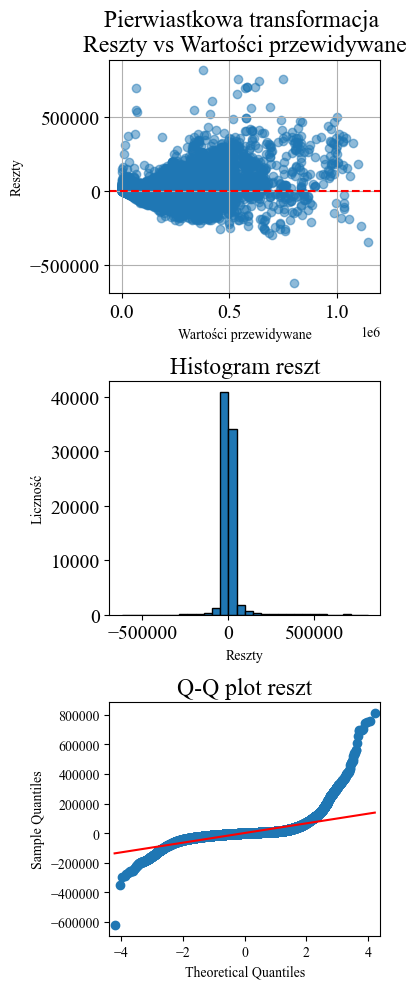

In [78]:
y_sqrt_train_pred = regresja.predict(X_sqrt_train)
residuals = y_sqrt_train**2 - y_sqrt_train_pred**2


fig, axs = plt.subplots(3, 1, figsize=(4, 10))

# 1. Residuals vs. predicted values
axs[0].scatter(y_sqrt_train_pred**2, residuals, alpha=0.5)
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel('Wartości przewidywane')
axs[0].set_ylabel('Reszty')
axs[0].set_title('Pierwiastkowa transformacja \nReszty vs Wartości przewidywane', fontsize=17)
axs[0].grid()
axs[0].tick_params(axis='x', labelsize=14)
axs[0].tick_params(axis='y', labelsize=14)

# 2. Residual histogram
axs[1].hist(residuals, bins=30, edgecolor='k')
axs[1].set_title('Histogram reszt', fontsize=17)
axs[1].set_xlabel('Reszty')
axs[1].set_ylabel('Liczność')
axs[1].tick_params(axis='x', labelsize=14)
axs[1].tick_params(axis='y', labelsize=14)

# 3. Residual Q-Q plot
import statsmodels.api as sm
sm.qqplot(residuals, line='s', ax=axs[2])
axs[2].set_title('Q-Q plot reszt', fontsize=17)

plt.tight_layout()
plt.show()



#### 4.6.2 Residual Diagnostics

Residual diagnostic statistics are calculated for the square-root-target model.

In [79]:

dw = durbin_watson(residuals)
print(f'Wartość statystyki Durbin-Watsona: {dw:.2f}')

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f'Shapiro-Wilk test: stat={shapiro_stat:.4f}, p-value={shapiro_p:.4g}')

X = sm.add_constant(X_sqrt_train.toarray())
gq_test = het_goldfeldquandt(y_sqrt_train, X)
print(f"Goldfeld-Quandt test: stat={gq_test[0]:.4f}, p-value={gq_test[1]:.4g}")



Wartość statystyki Durbin-Watsona: 2.00
Shapiro-Wilk test: stat=0.6036, p-value=2.644e-147


Goldfeld-Quandt test: stat=1.0241, p-value=0.008963


## 4.7 Ridge Regression: Original Target

Ridge regression with alpha 0.1 is fitted to the original price target and evaluated on the test set.

In [147]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=0.1, random_state=50)
ridge.fit(X_train, y_train)
y_pred_Ridge = ridge.predict(X_test)
MAPE_Ridge = mean_absolute_percentage_error(y_test, y_pred_Ridge)
MAE_Ridge = mean_absolute_error(y_pred_Ridge, y_test)


## 4.8 Ridge Regression: Log-Transformed Target

Ridge regression with alpha 1 is fitted to log(price); predictions are exponentiated for evaluation in PLN.

In [148]:
ridge = Ridge(alpha=1, random_state=50)
ridge.fit(X_log_train, y_log_train)
y_pred_Ridge_log = ridge.predict(X_log_test)
MAPE_Ridge_log = mean_absolute_percentage_error(
    np.exp(y_log_test), np.exp(y_pred_Ridge_log)
)
MAE_Ridge_log = mean_absolute_error(np.exp(y_pred_Ridge_log), np.exp(y_log_test))


## 4.9 Ridge Regression: Square-Root-Transformed Target

Ridge regression with alpha 0.001 is fitted to square-root(price); predictions are squared for evaluation in PLN.

In [149]:
ridge = Ridge(alpha=0.001, random_state=50)
ridge.fit(X_sqrt_train, y_sqrt_train)
y_pred_Ridge_sqrt = ridge.predict(X_sqrt_test)
MAPE_Ridge_sqrt = mean_absolute_percentage_error(
    np.square(y_sqrt_test), np.square(y_pred_Ridge_sqrt)
)
MAE_Ridge_sqrt = mean_absolute_error(
    np.square(y_sqrt_test), np.square(y_pred_Ridge_sqrt)
)


## 4.10 Random Forest: Original Target

A Random Forest with 300 trees and 50 selected features is fitted to the original price target.

In [150]:
from sklearn.ensemble import RandomForestRegressor

Forest = RandomForestRegressor(
    n_jobs=-1, max_features=50, n_estimators=300, random_state=50
)
Forest.fit(X_train, y_train)
y_pred_Las = Forest.predict(X_test)
MAE_las = mean_absolute_error(y_test, y_pred_Las)
MAPE_las = mean_absolute_percentage_error(y_test, y_pred_Las)


## 4.11 Random Forest: Log-Transformed Target

The Random Forest is fitted to log(price), and predictions are exponentiated for evaluation in PLN.

In [151]:
Forest = RandomForestRegressor(
    n_jobs=-1, max_features=50, n_estimators=300, random_state=50
)
Forest.fit(X_log_train, y_log_train)
y_pred_Las_log = Forest.predict(X_log_test)
MAPE_las_log = mean_absolute_percentage_error(
    np.exp(y_log_test), np.exp(y_pred_Las_log)
)
MAE_las_log = mean_absolute_error(np.exp(y_log_test), np.exp(y_pred_Las_log))


## 4.12 Random Forest: Square-Root-Transformed Target

The Random Forest is fitted to square-root(price), and predictions are squared for evaluation in PLN.

In [152]:
Forest = RandomForestRegressor(
    n_jobs=-1, max_features=50, n_estimators=300, random_state=50
)
Forest.fit(X_sqrt_train, y_sqrt_train)
y_pred_Las_sqrt = Forest.predict(X_sqrt_test)
MAPE_las_sqrt = mean_absolute_percentage_error(
    np.square(y_sqrt_test), np.square(y_pred_Las_sqrt)
)
MAE_las_sqrt = mean_absolute_error(np.square(y_sqrt_test), np.square(y_pred_Las_sqrt))


## 4.13 Multilayer Perceptron: Original Target

The multilayer perceptron provides a neural-network comparison to the regression and tree-based methods. Its hidden-layer architecture is selected in the tuning study, and separate models are fitted for the original, logarithmic, and square-root price targets.

In [153]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

Network = MLPRegressor(
    hidden_layer_sizes=(500, 300, 150),
    activation="relu",
    learning_rate="constant",
    batch_size="auto",
    early_stopping=True,
    random_state=50,
)
Network.fit(X_train, y_train)
y_pred_MLP = Network.predict(X_test)
MAE_MLP = mean_absolute_error(y_test, y_pred_MLP)
MAPE_MLP = mean_absolute_percentage_error(y_test, y_pred_MLP)


## 4.14 Multilayer Perceptron: Log-Transformed Target

A multilayer perceptron with 300 hidden units is fitted to log(price); predictions are exponentiated for evaluation in PLN.

In [154]:
Network = MLPRegressor(
    hidden_layer_sizes=(300),
    activation="relu",
    learning_rate="constant",
    batch_size="auto",
    early_stopping=True,
    random_state=50,
)
Network.fit(X_log_train, y_log_train)
y_pred_MLP_log = Network.predict(X_log_test)
MAE_MLP_log = mean_absolute_error(np.exp(y_log_test), np.exp(y_pred_MLP_log))
MAPE_MLP_log = mean_absolute_percentage_error(
    np.exp(y_log_test), np.exp(y_pred_MLP_log)
)


## 4.15 Multilayer Perceptron: Square-Root-Transformed Target

A multilayer perceptron with 500 hidden units is fitted to square-root(price); predictions are squared for evaluation in PLN.

In [155]:
Network = MLPRegressor(
    hidden_layer_sizes=(500),
    activation="relu",
    learning_rate="constant",
    batch_size="auto",
    early_stopping=True,
    random_state=50,
)
Network.fit(X_sqrt_train, y_sqrt_train)
y_pred_MLP_sqrt = Network.predict(X_sqrt_test)
MAE_MLP_sqrt = mean_absolute_error(np.square(y_sqrt_test), np.square(y_pred_MLP_sqrt))
MAPE_MLP_sqrt = mean_absolute_percentage_error(
    np.square(y_sqrt_test), np.square(y_pred_MLP_sqrt)
)


## 4.16 XGBoost: Original Target

XGBoost is fitted to the original price target using the selected model settings.

In [204]:
import xgboost as xgb


xgb_model = xgb.XGBRegressor(
    objective='reg:linear', verbosity=0,
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=12,
    random_state=50
)

xgb_model.fit(X_train, y_train,)
y_pred_XGB=xgb_model.predict(X_test)
MAE_XGB=mean_absolute_error(y_test,y_pred_XGB)
MAPE_XGB=mean_absolute_percentage_error(y_test,y_pred_XGB)

## 4.17 XGBoost: Log-Transformed Target

XGBoost is fitted to log(price), and predictions are exponentiated for evaluation in PLN.

In [209]:

xgb_model=xgb.XGBRegressor(objective='reg:linear', verbosity=0,n_estimators=1000,learning_rate=0.1,max_depth=10,random_state=50)
xgb_model.fit(X_log_train, y_log_train)
y_pred_XGB_log=xgb_model.predict(X_log_test)
MAPE_XGB_log=mean_absolute_percentage_error(np.exp(y_log_test),np.exp(y_pred_XGB_log))
MAE_XGB_log=mean_absolute_error(np.exp(y_log_test),np.exp(y_pred_XGB_log))

## 4.18 XGBoost: Square-Root-Transformed Target

XGBoost is fitted to square-root(price), and predictions are squared for evaluation in PLN.

In [158]:

xgb_model = xgb.XGBRegressor(objective='reg:linear', verbosity=0, n_estimators=1000, learning_rate=0.1, max_depth=10,random_state=50)
xgb_model.fit(X_sqrt_train, y_sqrt_train)
y_pred_XGB_sqrt = xgb_model.predict(X_sqrt_test)
MAPE_XGB_sqrt = mean_absolute_percentage_error(np.square(y_sqrt_test), np.square(y_pred_XGB_sqrt))
MAE_XGB_sqrt = mean_absolute_error(np.square(y_sqrt_test), np.square(y_pred_XGB_sqrt))

# 5. Study Results and Model Comparison

The final chapter brings together the held-out prediction examples, MAPE and MAE comparisons, and the XGBoost feature-importance ranking. The results summarize predictive performance on the price scale and identify the features most influential to the fitted tree-boosting model.

## 5.1 Example Predictions

The table compares actual prices with predictions from each model variant for 20 test-set observations.

In [159]:
comparison_table = pd.DataFrame({
    'Actual': np.exp(y_log_test),
    'MLPLog': np.exp(y_pred_MLP_log),
    'MLP': y_pred_MLP,
    'LogLinear': np.exp(y_pred_Reg_log),
    'RidgeLog': np.exp(y_pred_Ridge_log),
    'laslosLog': np.exp(y_pred_Las_log),
    'xgboostLog': np.exp(y_pred_XGB_log),
    'Linear': y_pred_Reg,
    'Ridge': y_pred_Ridge,
    'laslos': y_pred_Las,
    'xgboost': y_pred_XGB,
    'MLPSqrt': np.square(y_pred_MLP_sqrt),
    'LinearSqrt': np.square(y_pred_Reg_sqrt),
    'RidgeSqrt': np.square(y_pred_Ridge_sqrt),
    'laslosSqrt': np.square(y_pred_Las_sqrt),
    'xgboostSqrt': np.square(y_pred_XGB_sqrt),
})


comparison_table.tail(20)

,Actual,MLPLog,MLP,LogLinear,RidgeLog,laslosLog,xgboostLog,Linear,Ridge,laslos,xgboost,MLPSqrt,LinearSqrt,RidgeSqrt,laslosSqrt,xgboostSqrt
60951,146000.031250,152970.251689,150897.777619,162439.386158,162893.670290,144302.546266,150636.734375,155420.613738,155601.130825,144473.052857,150101.078125,150787.929993,160243.573484,160267.474671,144406.553577,150372.000000
40483,37900.007812,39247.446479,37287.797729,41436.552645,41568.834222,34053.172386,34856.601562,64724.885271,64732.115556,35613.870000,36171.324219,39998.545729,52158.092121,52167.634390,34391.830065,35086.574219
68422,46899.980469,38482.581634,43336.728936,41277.445003,41108.015794,45902.397866,45215.894531,37456.830602,37401.004925,46193.690000,46499.617188,42792.052605,41504.501217,41543.038832,46429.410591,46026.386719
184346,64500.027344,58791.548267,59346.023982,50386.356468,50444.568006,67452.879475,66027.023438,62679.951176,62917.735756,69050.966667,67648.593750,61504.596202,57566.309641,57621.933473,67975.681275,64772.578125
24519,214900.046875,200660.324732,208804.207711,214162.184988,214036.724136,211858.196879,213503.421875,183435.056537,183422.738145,214226.593333,214540.359375,205697.971550,189954.818070,190032.900471,216575.944351,205082.796875
5586,113989.953125,115331.255702,116224.240974,107277.336269,107078.978912,107510.970295,113392.648438,129348.022942,129273.425935,107072.916667,115085.859375,121934.312446,119152.388947,119086.296893,106263.601823,107571.125000
43198,18900.000000,17984.586480,18683.312999,19016.424284,18969.798312,16480.632833,18962.755859,-12194.352069,-12118.948733,16590.320000,18628.171875,18409.420229,13469.934995,13488.596183,16353.915230,19762.642578
96098,91018.015625,86813.237450,93555.635564,80152.742522,79974.622885,82558.870279,86252.234375,102776.453872,102866.513257,86252.960000,87067.320312,100508.349165,91299.088169,91354.896309,84554.478546,79696.039062
158628,52900.003906,53427.274336,56171.723133,55908.108368,55807.850911,51530.725938,57710.691406,58613.954116,58658.799950,54310.133333,58080.050781,61914.050737,58973.002270,59027.397784,53942.829364,57505.585938
158924,99000.015625,81520.064720,79009.064217,77689.561368,77207.800378,77511.388595,82181.515625,142089.751675,141897.073103,79526.781667,80462.125000,77819.498100,105479.107469,105401.074934,78782.833638,81280.304688


The sample displays actual and predicted prices for 20 held-out vehicles across the model variants.

## 5.2 Error Metrics

The table reports MAPE and MAE for each model and target representation. XGBoost with the square-root target has the lowest MAE in the displayed results, at approximately PLN 8,325.

In [184]:
errors_table = pd.DataFrame({
    'MLPLog': {'MAPE': MAPE_MLP_log, 'MAE': MAE_MLP_log},
    'MLP': {'MAPE': MAPE_MLP, 'MAE': MAE_MLP},
    'MLPSqrt': {'MAPE': MAPE_MLP_sqrt, 'MAE': MAE_MLP_sqrt},
    'LogLinear': {'MAPE': MAPE_Reg_log, 'MAE': MAE_Reg_log},
    'Linear': {'MAPE': MAPE_Reg, 'MAE': MAE_Reg},
    'LinearSqrt': {'MAPE': MAPE_Reg_sqrt, 'MAE': MAE_Reg_sqrt},
    'RidgeLog': {'MAPE': MAPE_Ridge_log, 'MAE': MAE_Ridge_log},
    'Ridge': {'MAPE': MAPE_Ridge, 'MAE': MAE_Ridge},
    'RidgeSqrt': {'MAPE': MAPE_Ridge_sqrt, 'MAE': MAE_Ridge_sqrt},
    'laslosLog': {'MAPE': MAPE_las_log, 'MAE': MAE_las_log},
    'laslos': {'MAPE': MAPE_las, 'MAE': MAE_las},
    'laslosSqrt': {'MAPE': MAPE_las_sqrt, 'MAE': MAE_las_sqrt},
    'xgboostLog': {'MAPE': MAPE_XGB_log, 'MAE': MAE_XGB_log},
    'xgboost': {'MAPE': MAPE_XGB, 'MAE': MAE_XGB},
    'xgboostSqrt': {'MAPE': MAPE_XGB_sqrt, 'MAE': MAE_XGB_sqrt}
})

errors_table.to_csv('errors_table.csv')
errors_table

,MLPLog,MLP,MLPSqrt,LogLinear,Linear,LinearSqrt,RidgeLog,Ridge,RidgeSqrt,laslosLog,laslos,laslosSqrt,xgboostLog,xgboost,xgboostSqrt
MAPE,0.107204,0.105164,0.102277,0.156961,1.805202,2.744044,0.157192,3.052490,2.767581,0.114423,0.122265,0.116835,0.099327,0.101921,0.100186
MAE,9282.388527,8384.570532,8353.539321,12984.364364,25436.292412,15344.922664,12965.810923,25441.211813,15344.473613,9808.866658,9514.655261,9560.761800,8357.212891,8372.809570,8325.394531


## 5.3 XGBoost Feature Importance

The fitted XGBoost model assigns the highest feature importance to vehicle age (`car_age`), followed by the EQS and 911 model indicators, SUV body type, and engine power.

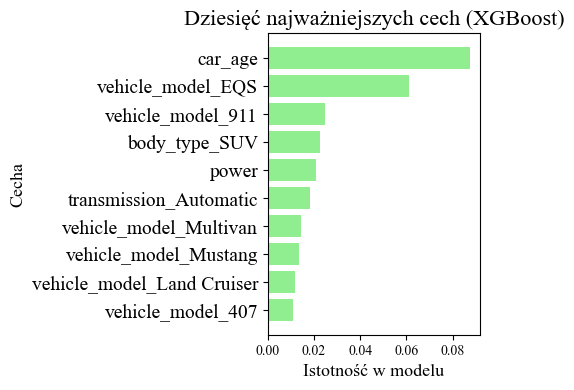

In [192]:

importances = xgb_model.feature_importances_

feature_names = []
feature_names.extend(numeric_features)
feature_names.extend(
    preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
)

indices = np.argsort(importances)[::-1]
sorted_importances = importances[indices]
sorted_feature_names = np.array(feature_names)[indices]

plt.figure(figsize=(5, 4))
plt.barh(range(10), sorted_importances[:10][::-1], color='#90ee90')
plt.yticks(range(10), sorted_feature_names[:10][::-1])
plt.title('Dziesięć najważniejszych cech (XGBoost)', fontsize=16)
plt.ylabel('Cecha', fontsize=13)
plt.xlabel('Istotność w modelu', fontsize=13)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

## 5.4 Overall Study Summary

The study began with 208,205 vehicle-listing observations and 224 analysis columns. Data preparation converted prices to PLN, derived vehicle age and seller experience, handled missing values, excluded damaged or accident-affected offers, applied the selected extreme-value filters, and retained vehicle models with at least 100 observations. After the additional fuel-type filtering used for the descriptive statistics, the analyzed sample contained 99,591 listings.

Exploratory analysis described price, mileage, engine displacement, power, vehicle age, seller experience, and categorical vehicle attributes. The median price was PLN 63,500 and the mean was approximately PLN 98,906; median mileage was 130,260 km and median vehicle age was 7 years. Numerical features were standardized and categorical features were one-hot encoded, producing 289 model inputs. The held-out modeling workflow used an 80/20 train-test split.

Five model families were compared across the original, logarithmic, and square-root representations of price. In the recorded results, **XGBoost with a log-transformed target had the lowest displayed MAPE at 0.0993 (approximately 9.93%)**. XGBoost with a square-root-transformed target had the lowest MAE at approximately PLN 8,325. The feature-importance ranking placed vehicle age first, followed by the EQS and 911 model indicators, SUV body type, and engine power. Overall, XGBoost delivered the strongest displayed price-error results, while the feature-importance analysis highlighted vehicle age and model-specific effects as influential predictors.